In [3]:
!git clone -b megha-work https://github.com/mansiguptacs/CMPE_258_TrafficForecastingUsing_GraphNN.git

Cloning into 'CMPE_258_TrafficForecastingUsing_GraphNN'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 107 (delta 36), reused 81 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (107/107), 945.68 KiB | 2.31 MiB/s, done.
Resolving deltas: 100% (36/36), done.


In [4]:
%cd CMPE_258_TrafficForecastingUsing_GraphNN

/content/CMPE_258_TrafficForecastingUsing_GraphNN


In [5]:
!pip install -r requirements.txt -q

In [6]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [7]:
!mkdir -p data/raw data/processed

In [8]:
!cp -r "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/raw/." data/raw/
!cp -r "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/data/processed/." data/processed/

In [9]:
!ls -lh data/raw
!ls -lh data/processed

total 1.2M
-rw------- 1 root root  286 Oct 30 21:04 adj_correlation_metadata.json
-rw------- 1 root root 168K Oct 30 21:04 adj_correlation.npy
-rw------- 1 root root  306 Oct 30 21:04 adj_distance_metadata.json
-rw------- 1 root root 168K Oct 30 21:04 adj_distance.npy
-rw------- 1 root root 665K Oct 30 21:04 adj_mx.pkl
-rw------- 1 root root 104K Oct 30 21:04 correlation_graph_heatmap.png
-rw------- 1 root root  86K Oct 30 21:04 distance_graph_heatmap.png
-rw------- 1 root root  240 Oct 30 21:04 graph_comparison_metadata.json
total 32M
-rw------- 1 root root  898 Oct 30 21:04 meta.json
-rw------- 1 root root  32M Oct 30 21:04 metr_la_processed.npz
-rw------- 1 root root 7.9K Oct 30 21:04 scalers.json


In [10]:
import numpy as np
import os

processed = np.load(
    "data/processed/metr_la_processed.npz"
)

distance_graph = np.load(
    "data/raw/adj_distance.npy"
)

print("Processed data:", processed.files)
print("Distance graph shape:", distance_graph.shape)
print("Distance graph nonzero values:", (distance_graph > 0).sum())

Processed data: ['speeds', 'inputs', 'observed', 'timestamps', 'sensor_ids', 'adj_distance']
Distance graph shape: (207, 207)
Distance graph nonzero values: 1596


In [11]:
import json

print("Inputs shape:", processed["inputs"].shape)
print("Speeds shape:", processed["speeds"].shape)
print("Observed shape:", processed["observed"].shape)

with open("data/processed/meta.json") as f:
    meta = json.load(f)

print("Metadata:")
print(meta)

Inputs shape: (34272, 207)
Speeds shape: (34272, 207)
Observed shape: (34272, 207)
Metadata:
{'shape': {'timesteps': 34272, 'sensors': 207}, 'time_range': ['2012-03-01 00:00:00', '2012-06-27 23:55:00'], 'split_index': {'train': [0, 23990], 'val': [23990, 27417], 'test': [27417, 34272]}, 'split_time': {'train': ['2012-03-01 00:00:00', '2012-05-23 07:05:00'], 'val': ['2012-05-23 07:10:00', '2012-06-04 04:40:00'], 'test': ['2012-06-04 04:45:00', '2012-06-27 23:55:00']}, 'missing_pct_overall': 8.109350825676486, 'missing_pct_by_split': {'train': 7.132198802641197, 'val': 6.962188587643733, 'test': 12.102523987216214}, 'fully_missing_steps': 2148, 'input_imputation': 'ffill', 'windows': {'input_len': 12, 'horizons': [3, 6, 12], 'output_len': 12}}


In [12]:
import numpy as np

print("Inputs:")
print("Minimum:", np.nanmin(processed["inputs"]))
print("Maximum:", np.nanmax(processed["inputs"]))
print("Mean:", np.nanmean(processed["inputs"]))

print("\nSpeeds:")
print("Minimum:", np.nanmin(processed["speeds"]))
print("Maximum:", np.nanmax(processed["speeds"]))
print("Mean:", np.nanmean(processed["speeds"]))

Inputs:
Minimum: -30.952944
Maximum: 6.9350677
Mean: -0.017489977

Speeds:
Minimum: 0.0
Maximum: 70.0
Mean: 53.719006


In [13]:
with open("data/processed/scalers.json") as f:
    scalers = json.load(f)

print(type(scalers))

if isinstance(scalers, dict):
    print(scalers.keys())
    for key, value in scalers.items():
        print(key, type(value))
        print(str(value)[:300])

<class 'dict'>
dict_keys(['mean', 'std'])
mean <class 'list'>
[61.91374969482422, 64.42971801757812, 64.68721008300781, 52.96262741088867, 49.83348846435547, 55.02029037475586, 58.47807693481445, 63.20731735229492, 60.708221435546875, 56.88612747192383, 60.429893493652344, 63.0880126953125, 40.955570220947266, 64.28522491455078, 55.727447509765625, 49.91772460
std <class 'list'>
[11.677257537841797, 3.45369553565979, 9.789295196533203, 9.384199142456055, 14.877752304077148, 10.517891883850098, 11.152555465698242, 2.888857126235962, 8.525444030761719, 19.073104858398438, 4.5486040115356445, 3.679403066635132, 23.22530174255371, 7.048783302307129, 14.129961013793945, 14.83228


In [14]:
import numpy as np

sensor_mean = np.array(
    scalers["mean"],
    dtype=np.float32
)

sensor_std = np.array(
    scalers["std"],
    dtype=np.float32
)

speed_raw = processed["speeds"].astype(np.float32)
input_data = processed["inputs"].astype(np.float32)
observed = processed["observed"].astype(bool)

target_data = (
    speed_raw - sensor_mean
) / sensor_std

input_len = 12
output_len = 12

split_ranges = {
    "train": (0, 23990),
    "val": (23990, 27417),
    "test": (27417, 34272)
}

def create_windows(start, end):
    X = []
    Y = []
    M = []

    last_start = end - input_len - output_len + 1

    for t in range(start, last_start):
        X.append(
            input_data[t:t + input_len]
        )

        Y.append(
            target_data[
                t + input_len:
                t + input_len + output_len
            ]
        )

        M.append(
            observed[
                t + input_len:
                t + input_len + output_len
            ]
        )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(Y, dtype=np.float32),
        np.asarray(M, dtype=bool)
    )

train_X, train_Y, train_M = create_windows(
    *split_ranges["train"]
)

val_X, val_Y, val_M = create_windows(
    *split_ranges["val"]
)

test_X, test_Y, test_M = create_windows(
    *split_ranges["test"]
)

print("Train:", train_X.shape, train_Y.shape)
print("Validation:", val_X.shape, val_Y.shape)
print("Test:", test_X.shape, test_Y.shape)

Train: (23967, 12, 207) (23967, 12, 207)
Validation: (3404, 12, 207) (3404, 12, 207)
Test: (6832, 12, 207) (6832, 12, 207)


In [15]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def create_loader(X, Y, M, batch_size, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(Y),
        torch.from_numpy(M.astype(np.float32))
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

train_loader = create_loader(
    train_X, train_Y, train_M, batch_size=32, shuffle=True
)

val_loader = create_loader(
    val_X, val_Y, val_M, batch_size=32, shuffle=False
)

test_loader = create_loader(
    test_X, test_Y, test_M, batch_size=32, shuffle=False
)

adj = distance_graph.astype(np.float32)

row_sum = adj.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0

forward_random_walk = adj / row_sum

reverse_adj = adj.T
reverse_row_sum = reverse_adj.sum(axis=1, keepdims=True)
reverse_row_sum[reverse_row_sum == 0] = 1.0

backward_random_walk = reverse_adj / reverse_row_sum

supports = [
    torch.tensor(forward_random_walk, dtype=torch.float32),
    torch.tensor(backward_random_walk, dtype=torch.float32)
]

print("Device:", device)
print("Number of training batches:", len(train_loader))
print("Forward support shape:", supports[0].shape)
print("Backward support shape:", supports[1].shape)

Device: cuda
Number of training batches: 749
Forward support shape: torch.Size([207, 207])
Backward support shape: torch.Size([207, 207])


In [16]:
import torch.nn as nn

class DiffusionGraphConv(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        supports,
        max_diffusion_step=2
    ):
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.max_diffusion_step = max_diffusion_step

        for index, support in enumerate(supports):
            self.register_buffer(
                f"support_{index}",
                support
            )

        total_inputs = (
            input_dim *
            (1 + len(supports) * max_diffusion_step)
        )

        self.projection = nn.Linear(
            total_inputs,
            output_dim
        )

    def forward(self, x):
        # x shape: (batch, sensors, features)
        features = [x]

        for index in range(len(supports)):
            support = getattr(
                self,
                f"support_{index}"
            )

            propagated = x

            for _ in range(self.max_diffusion_step):
                propagated = torch.einsum(
                    "nm,bmc->bnc",
                    support,
                    propagated
                )

                features.append(propagated)

        combined = torch.cat(features, dim=-1)

        return self.projection(combined)

In [17]:
class DCGRUCell(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim,
        supports,
        max_diffusion_step=2
    ):
        super().__init__()

        self.hidden_dim = hidden_dim

        self.gate = DiffusionGraphConv(
            input_dim=input_dim + hidden_dim,
            output_dim=2 * hidden_dim,
            supports=supports,
            max_diffusion_step=max_diffusion_step
        )

        self.candidate = DiffusionGraphConv(
            input_dim=input_dim + hidden_dim,
            output_dim=hidden_dim,
            supports=supports,
            max_diffusion_step=max_diffusion_step
        )

    def forward(self, x, hidden):
        combined = torch.cat(
            [x, hidden],
            dim=-1
        )

        gates = torch.sigmoid(
            self.gate(combined)
        )

        update_gate, reset_gate = torch.chunk(
            gates,
            chunks=2,
            dim=-1
        )

        reset_hidden = reset_gate * hidden

        candidate_input = torch.cat(
            [x, reset_hidden],
            dim=-1
        )

        candidate_hidden = torch.tanh(
            self.candidate(candidate_input)
        )

        new_hidden = (
            (1 - update_gate) * hidden
            + update_gate * candidate_hidden
        )

        return new_hidden

In [18]:
sample_X, _, _ = next(iter(train_loader))

sample_x = sample_X[:, 0, :].unsqueeze(-1)
sample_x = sample_x.to(device)

sample_hidden = torch.zeros(
    sample_x.size(0),
    sample_x.size(1),
    32,
    device=device
)

test_cell = DCGRUCell(
    input_dim=1,
    hidden_dim=32,
    supports=supports
).to(device)

cell_output = test_cell(
    sample_x,
    sample_hidden
)

print("Input shape:", sample_x.shape)
print("Cell output shape:", cell_output.shape)

Input shape: torch.Size([32, 207, 1])
Cell output shape: torch.Size([32, 207, 32])


In [19]:
class DCRNN(nn.Module):
    def __init__(
        self,
        num_nodes,
        input_dim=1,
        hidden_dim=32,
        output_len=12,
        supports=None
    ):
        super().__init__()

        self.num_nodes = num_nodes
        self.output_len = output_len
        self.hidden_dim = hidden_dim

        self.encoder = DCGRUCell(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            supports=supports
        )

        self.decoder = DCGRUCell(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            supports=supports
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            1
        )

    def forward(
        self,
        inputs,
        targets=None,
        teacher_forcing_ratio=0.0
    ):
        # inputs shape: (batch, input_steps, sensors)
        batch_size = inputs.size(0)

        hidden = torch.zeros(
            batch_size,
            self.num_nodes,
            self.hidden_dim,
            device=inputs.device
        )

        # Encoder
        for step in range(inputs.size(1)):
            encoder_input = inputs[:, step, :].unsqueeze(-1)
            hidden = self.encoder(
                encoder_input,
                hidden
            )

        # Decoder starts with the last observed input
        decoder_input = inputs[:, -1, :].unsqueeze(-1)

        predictions = []

        for step in range(self.output_len):
            hidden = self.decoder(
                decoder_input,
                hidden
            )

            prediction = self.output_layer(
                hidden
            ).squeeze(-1)

            predictions.append(prediction)

            use_teacher_forcing = (
                targets is not None
                and torch.rand(1).item()
                < teacher_forcing_ratio
            )

            if use_teacher_forcing:
                decoder_input = targets[
                    :, step, :
                ].unsqueeze(-1)
            else:
                decoder_input = prediction.unsqueeze(-1)

        return torch.stack(
            predictions,
            dim=1
        )

In [21]:
dcrnn = DCRNN(
    num_nodes=207,
    input_dim=1,
    hidden_dim=32,
    output_len=12,
    supports=supports
).to(device)

sample_X, sample_Y, _ = next(iter(train_loader))

sample_X = sample_X.to(device)
sample_Y = sample_Y.to(device)

sample_predictions = dcrnn(
    sample_X,
    targets=sample_Y,
    teacher_forcing_ratio=0.5
)

print("Input shape:", sample_X.shape)
print("Prediction shape:", sample_predictions.shape)

Input shape: torch.Size([32, 12, 207])
Prediction shape: torch.Size([32, 12, 207])


In [22]:
def masked_mae_loss(predictions, targets, mask):
    absolute_error = torch.abs(
        predictions - targets
    )

    masked_error = absolute_error * mask

    return masked_error.sum() / mask.sum().clamp_min(1.0)

In [23]:
optimizer = torch.optim.Adam(
    dcrnn.parameters(),
    lr=0.001
)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in dcrnn.parameters()
        if parameter.requires_grad
    )
)

Trainable parameters: 31905


In [24]:
dcrnn.train()

batch_X, batch_Y, batch_M = next(
    iter(train_loader)
)

batch_X = batch_X.to(device)
batch_Y = batch_Y.to(device)
batch_M = batch_M.to(device)

optimizer.zero_grad()

batch_predictions = dcrnn(
    batch_X,
    targets=batch_Y,
    teacher_forcing_ratio=0.5
)

batch_loss = masked_mae_loss(
    batch_predictions,
    batch_Y,
    batch_M
)

batch_loss.backward()

torch.nn.utils.clip_grad_norm_(
    dcrnn.parameters(),
    max_norm=5.0
)

optimizer.step()

print("Batch prediction shape:", batch_predictions.shape)
print("Batch loss:", batch_loss.item())

Batch prediction shape: torch.Size([32, 12, 207])
Batch loss: 0.6934695243835449


In [2]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [25]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0

    for X, Y, M in loader:
        X = X.to(device)
        Y = Y.to(device)
        M = M.to(device)

        optimizer.zero_grad()

        predictions = model(
            X,
            targets=Y,
            teacher_forcing_ratio=0.5
        )

        loss = masked_mae_loss(
            predictions,
            Y,
            M
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for X, Y, M in loader:
            X = X.to(device)
            Y = Y.to(device)
            M = M.to(device)

            predictions = model(X)

            loss = masked_mae_loss(
                predictions,
                Y,
                M
            )

            total_loss += loss.item()

    return total_loss / len(loader)


history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
num_epochs = 10

for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(
        dcrnn,
        train_loader
    )

    val_loss = evaluate_loss(
        dcrnn,
        val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            dcrnn.state_dict(),
            "dcrnn_distance_best.pt"
        )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch 01 | Train Loss: 0.3343 | Validation Loss: 0.3696
Epoch 02 | Train Loss: 0.3046 | Validation Loss: 0.3617
Epoch 03 | Train Loss: 0.3015 | Validation Loss: 0.3590
Epoch 04 | Train Loss: 0.2984 | Validation Loss: 0.3535
Epoch 05 | Train Loss: 0.2963 | Validation Loss: 0.3557
Epoch 06 | Train Loss: 0.2957 | Validation Loss: 0.3515
Epoch 07 | Train Loss: 0.2936 | Validation Loss: 0.3500
Epoch 08 | Train Loss: 0.2923 | Validation Loss: 0.3485
Epoch 09 | Train Loss: 0.2914 | Validation Loss: 0.3528
Epoch 10 | Train Loss: 0.2902 | Validation Loss: 0.3437


In [26]:
dcrnn.load_state_dict(
    torch.load(
        "dcrnn_distance_best.pt",
        map_location=device
    )
)

dcrnn.eval()

print("Best DCRNN checkpoint loaded.")

Best DCRNN checkpoint loaded.


In [27]:
dcrnn.load_state_dict(
    torch.load(
        "dcrnn_distance_best.pt",
        map_location=device
    )
)

dcrnn.eval()

all_predictions = []
all_targets = []
all_masks = []

with torch.no_grad():
    for X, Y, M in test_loader:
        X = X.to(device)

        predictions = dcrnn(X)

        all_predictions.append(
            predictions.cpu().numpy()
        )
        all_targets.append(
            Y.numpy()
        )
        all_masks.append(
            M.numpy()
        )

pred_norm = np.concatenate(all_predictions)
target_norm = np.concatenate(all_targets)
target_mask = np.concatenate(all_masks).astype(bool)

# Convert normalized values back to mph
pred_mph = (
    pred_norm * sensor_std.reshape(1, 1, -1)
    + sensor_mean.reshape(1, 1, -1)
)

target_mph = (
    target_norm * sensor_std.reshape(1, 1, -1)
    + sensor_mean.reshape(1, 1, -1)
)

horizons = {
    "15 minutes": 2,
    "30 minutes": 5,
    "60 minutes": 11
}

for name, step in horizons.items():
    prediction = pred_mph[:, step, :]
    target = target_mph[:, step, :]
    mask = target_mask[:, step, :]

    error = prediction[mask] - target[mask]

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    valid_target = target[mask]
    mape = np.mean(
        np.abs(error) /
        np.maximum(np.abs(valid_target), 1e-5)
    ) * 100

    print(
        f"{name}: "
        f"MAE={mae:.4f}, "
        f"RMSE={rmse:.4f}, "
        f"MAPE={mape:.2f}%"
    )

15 minutes: MAE=2.9515, RMSE=5.6458, MAPE=7.73%
30 minutes: MAE=3.5231, RMSE=6.9425, MAPE=9.71%
60 minutes: MAE=4.3998, RMSE=8.6693, MAPE=12.68%


In [28]:
import os
import json

dcrnn_metrics = {
    "15_min": {
        "MAE": 2.9515,
        "RMSE": 5.6458,
        "MAPE": 7.73
    },
    "30_min": {
        "MAE": 3.5231,
        "RMSE": 6.9425,
        "MAPE": 9.71
    },
    "60_min": {
        "MAE": 4.3998,
        "RMSE": 8.6693,
        "MAPE": 12.68
    }
}

os.makedirs(
    "results/dcrnn_distance",
    exist_ok=True
)

with open(
    "results/dcrnn_distance/metrics.json",
    "w"
) as f:
    json.dump(dcrnn_metrics, f, indent=2)

print("DCRNN metrics saved.")

DCRNN metrics saved.


In [29]:
!mkdir -p "/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/results/dcrnn_distance"

!cp results/dcrnn_distance/metrics.json \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/results/dcrnn_distance/"

!cp dcrnn_distance_best.pt \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/results/dcrnn_distance/"

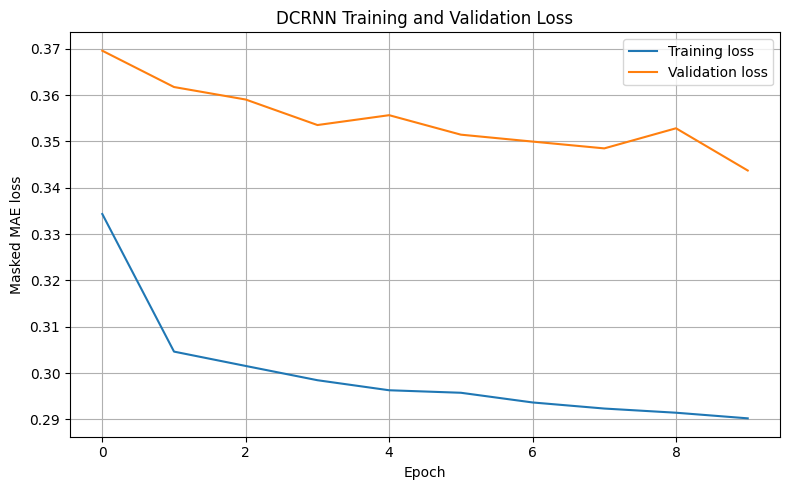

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    label="Training loss"
)

plt.plot(
    history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Masked MAE loss")
plt.title("DCRNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "results/dcrnn_distance/loss_curve.png",
    dpi=200
)

plt.show()

In [31]:
!cp results/dcrnn_distance/loss_curve.png \
"/content/drive/MyDrive/CMPE258_TrafficForecastingUsing_GraphNN/results/dcrnn_distance/"